In [2]:
# Experiment 9: Markov Model and Reinforcement Learning
# Aim: model a stochastic environment and learn a policy using Q-learning.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
N = 4
N_STATES = N * N
ACTIONS = ["UP", "RIGHT", "DOWN", "LEFT"]
ARROWS = ["↑", "→", "↓", "←"]
START, GOAL, PIT = 0, 15, 5
TERMINALS = {GOAL, PIT}

def move(state, action):
    r, c = divmod(state, N)
    if action == 0: r = max(0, r - 1)
    elif action == 1: c = min(N - 1, c + 1)
    elif action == 2: r = min(N - 1, r + 1)
    else: c = max(0, c - 1)
    return r * N + c

def transition_probs(state, action):
    """P(s'|s,a): 0.8 intended move, 0.1 to either perpendicular direction."""
    if state in TERMINALS: return {state: 1.0}
    outcomes = {}
    for actual, probability in [(action, 0.8), ((action - 1) % 4, 0.1), ((action + 1) % 4, 0.1)]:
        nxt = move(state, actual)
        outcomes[nxt] = outcomes.get(nxt, 0.0) + probability
    return outcomes

# Transition matrix under a uniform random policy.
P = np.zeros((N_STATES, N_STATES))
for s in range(N_STATES):
    for a in range(4):
        for nxt, prob in transition_probs(s, a).items():
            P[s, nxt] += 0.25 * prob

# Simulate a trajectory and estimate long-run state frequencies.
state, trajectory = START, [START]
visits = np.zeros(N_STATES)
for _ in range(300):
    action = np.random.randint(4)
    outcomes = list(transition_probs(state, action).items())
    state = int(np.random.choice([x[0] for x in outcomes], p=[x[1] for x in outcomes]))
    trajectory.append(state)
    visits[state] += 1

dist = np.zeros(N_STATES)
dist[START] = 1.0
for _ in range(500): dist = dist @ P

print("1. MARKOV MODEL")
print("States: 0-15 on a 4x4 grid; actions: up, right, down, left.")
print("Transition probabilities: 0.8 intended direction, 0.1 to each side; boundary moves stay in place.")
print("Long-run state distribution under a uniform random policy:")
print(np.round(dist.reshape(N, N), 3))


1. MARKOV MODEL
States: 0-15 on a 4x4 grid; actions: up, right, down, left.
Transition probabilities: 0.8 intended direction, 0.1 to each side; boundary moves stay in place.
Long-run state distribution under a uniform random policy:
[[0.    0.    0.    0.   ]
 [0.    0.883 0.    0.   ]
 [0.    0.    0.    0.   ]
 [0.    0.    0.    0.117]]


In [3]:
# 2. REWARD MODEL AND REUSABLE Q-LEARNING / EVALUATION FUNCTIONS
def reward_for(next_state, goal_reward=1.0, pit_penalty=-1.0):
    if next_state == GOAL: return goal_reward
    if next_state == PIT: return pit_penalty
    return -0.04  # small cost encourages shorter routes

def train_q_learning(goal_reward=1.0, pit_penalty=-1.0, epsilon=0.2, gamma=0.95,
                     episodes=1800, alpha=0.15, max_steps=80, seed=0):
    rng = np.random.default_rng(seed)
    q = np.zeros((N_STATES, 4))
    returns = []
    for ep in range(episodes):
        s, total = START, 0.0
        eps = max(0.02, epsilon * (1 - ep / episodes))
        for _ in range(max_steps):
            if rng.random() < eps:
                a = int(rng.integers(4))
            else:
                a = int(rng.choice(np.flatnonzero(q[s] == q[s].max())))
            outcomes = list(transition_probs(s, a).items())
            nxt = int(rng.choice([x[0] for x in outcomes], p=[x[1] for x in outcomes]))
            r = reward_for(nxt, goal_reward, pit_penalty)
            target = r if nxt in TERMINALS else r + gamma * np.max(q[nxt])
            q[s, a] += alpha * (target - q[s, a])
            total += r
            s = nxt
            if s in TERMINALS: break
        returns.append(total)
    return q, np.asarray(returns)

def evaluate_policy(q, episodes=300, max_steps=80, goal_reward=1.0, pit_penalty=-1.0, seed=123):
    rng = np.random.default_rng(seed)
    rewards, steps, successes = [], [], []
    for _ in range(episodes):
        s, total = START, 0.0
        for t in range(1, max_steps + 1):
            a = int(rng.choice(np.flatnonzero(q[s] == q[s].max())))
            outcomes = list(transition_probs(s, a).items())
            nxt = int(rng.choice([x[0] for x in outcomes], p=[x[1] for x in outcomes]))
            total += reward_for(nxt, goal_reward, pit_penalty)
            s = nxt
            if s in TERMINALS: break
        rewards.append(total); steps.append(t); successes.append(s == GOAL)
    return {"Cumulative Reward": np.mean(rewards), "Steps Taken": np.mean(steps),
            "Success Rate (%)": 100 * np.mean(successes)}

def show_policy(q, title):
    policy = np.argmax(q, axis=1)
    cells = ["G" if s == GOAL else "P" if s == PIT else "S" if s == START else ARROWS[policy[s]] for s in range(N_STATES)]
    print(title)
    print(pd.DataFrame(np.array(cells).reshape(N, N)))

print("2. Reward and Q-learning functions are ready.")


2. Reward and Q-learning functions are ready.


In [4]:
# 3. REWARD-BASED DECISIONS AND BASELINE Q-LEARNING
print("3. REWARD-BASED DECISION-MAKING")
q_mild, _ = train_q_learning(goal_reward=1, pit_penalty=-0.2, seed=1)
q_severe, _ = train_q_learning(goal_reward=1, pit_penalty=-5, seed=1)
show_policy(q_mild, "Policy with pit penalty = -0.2 (G=goal, P=pit, S=start):")
show_policy(q_severe, "Policy with pit penalty = -5:")

print("\n4. Q-LEARNING")
q_base, learning_returns = train_q_learning(goal_reward=1, pit_penalty=-1, epsilon=0.2, gamma=0.95, seed=2)
show_policy(q_base, "Learned greedy policy (G=goal, P=pit, S=start):")
print("Q-values by action (rows=states; columns=UP, RIGHT, DOWN, LEFT):")
print(pd.DataFrame(np.round(q_base, 2), columns=ACTIONS))


3. REWARD-BASED DECISION-MAKING
Policy with pit penalty = -0.2 (G=goal, P=pit, S=start):
   0  1  2  3
0  S  ←  ↓  ↑
1  ↓  P  ↓  ↓
2  ↓  ↓  →  ↓
3  →  →  →  G
Policy with pit penalty = -5:
   0  1  2  3
0  S  ↑  →  ↓
1  ←  P  →  ↓
2  ↓  ↓  ↓  ↓
3  →  →  →  G

4. Q-LEARNING
Learned greedy policy (G=goal, P=pit, S=start):
   0  1  2  3
0  S  ↑  ↓  ↓
1  ↑  P  →  ↓
2  ↓  ↓  ↓  ↓
3  →  →  →  G
Q-values by action (rows=states; columns=UP, RIGHT, DOWN, LEFT):
      UP  RIGHT  DOWN  LEFT
0   0.04   0.07  0.04  0.05
1   0.08   0.06 -0.94 -0.18
2   0.48   0.52  0.53  0.29
3   0.06   0.20  0.75  0.21
4  -0.01  -0.88 -0.30 -0.04
5   0.00   0.00  0.00  0.00
6   0.43   0.77  0.52 -0.56
7   0.50   0.73  0.85  0.59
8   0.37   0.58  0.65  0.55
9  -0.48   0.51  0.69  0.35
10  0.36   0.72  0.84  0.58
11  0.70   0.86  0.97  0.67
12  0.61   0.76  0.67  0.64
13  0.71   0.88  0.76  0.66
14  0.78   0.97  0.89  0.78
15  0.00   0.00  0.00  0.00


In [5]:
# 4-5. EXPLORATION VS. EXPLOITATION AND DISCOUNT FACTOR
settings, curves = [], {}
for eps in [0.05, 0.2, 0.6]:
    q, curve = train_q_learning(epsilon=eps, gamma=0.95, seed=10)
    curves[f"epsilon={eps}"] = curve
    settings.append({"Setting": f"epsilon={eps}", **evaluate_policy(q, seed=20)})
for gamma in [0.5, 0.95, 0.99]:
    q, curve = train_q_learning(epsilon=0.2, gamma=gamma, seed=30)
    curves[f"gamma={gamma}"] = curve
    settings.append({"Setting": f"gamma={gamma}", **evaluate_policy(q, seed=40)})

# Policy evaluation: average of 300 greedy-policy episodes.
results = pd.DataFrame(settings)
print("4-5. EPSILON AND DISCOUNT FACTOR EXPERIMENTS")
print("\n6. POLICY EVALUATION: cumulative reward, steps, and success rate")
print(results.round(3).to_string(index=False))

reward_results = pd.DataFrame([
    {"Setting": "pit penalty -0.2", **evaluate_policy(q_mild, pit_penalty=-0.2, seed=50)},
    {"Setting": "pit penalty -5", **evaluate_policy(q_severe, pit_penalty=-5, seed=50)},
])
print("\nReward-change comparison:")
print(reward_results.round(3).to_string(index=False))


4-5. EPSILON AND DISCOUNT FACTOR EXPERIMENTS

6. POLICY EVALUATION: cumulative reward, steps, and success rate
     Setting  Cumulative Reward  Steps Taken  Success Rate (%)
epsilon=0.05              0.609        7.117            92.667
 epsilon=0.2              0.473        7.353            86.333
 epsilon=0.6              0.527        7.483            89.333
   gamma=0.5              0.342       17.450           100.000
  gamma=0.95              0.495        7.800            88.333
  gamma=0.99              0.319       17.927            99.667

Reward-change comparison:
         Setting  Cumulative Reward  Steps Taken  Success Rate (%)
pit penalty -0.2              0.613        7.083              88.0
  pit penalty -5              0.364       16.893             100.0


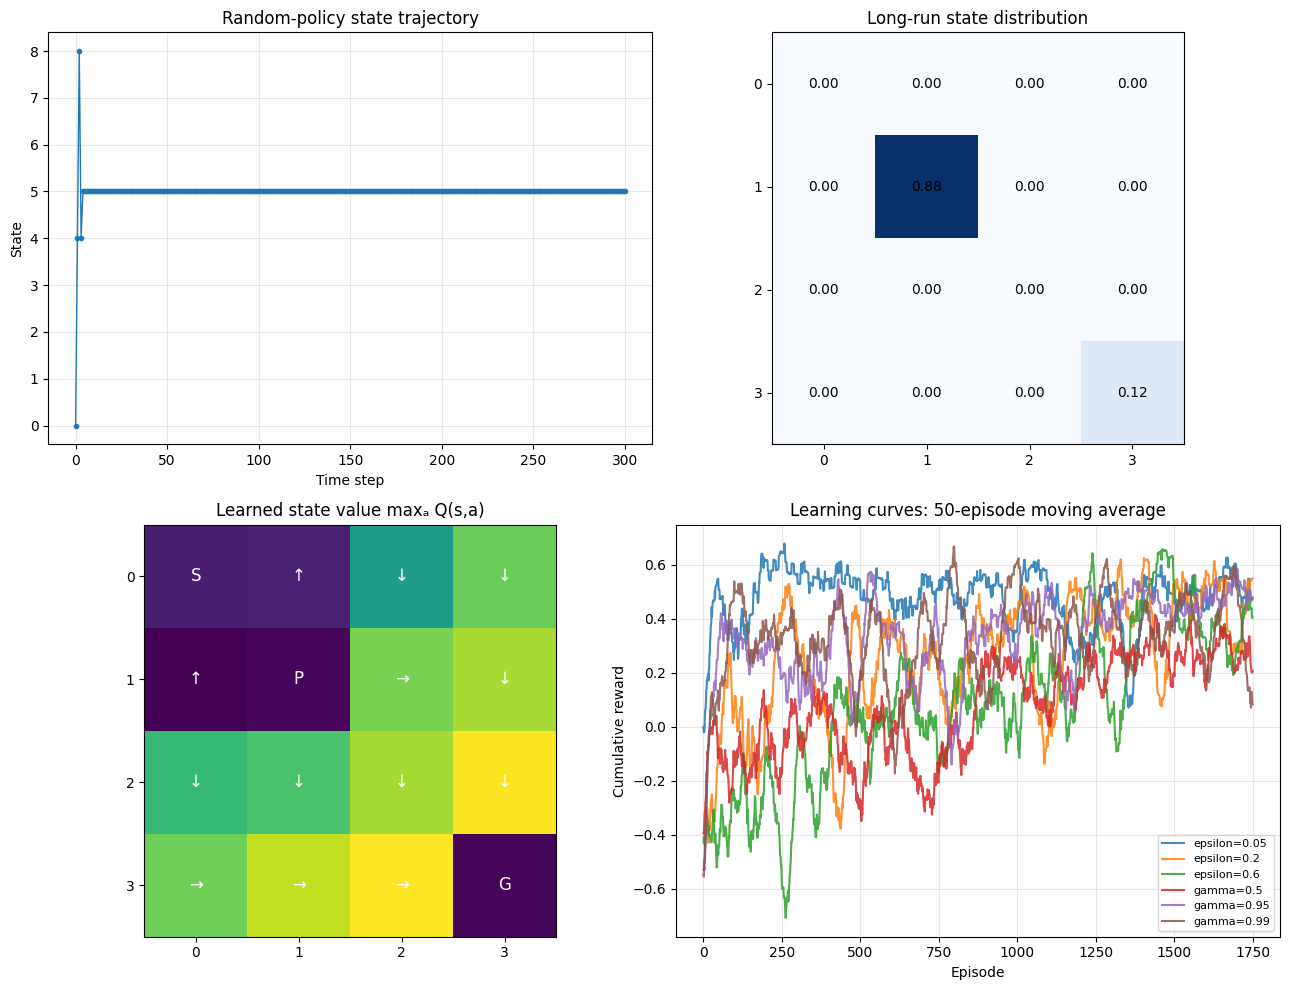

OBSERVATIONS
1. The transition matrix captures the Markov process; long-run distribution shows where a random policy settles.
2. Q-learning combines immediate reward and discounted future value to learn action values.
3. Epsilon controls exploration, while gamma controls the influence of future rewards.
4. Compare settings using cumulative reward, steps, and success rate; these measures may trade off.


In [6]:
# 7. VISUALIZATION AND OBSERVATIONS
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes[0, 0].plot(trajectory, marker=".", linewidth=1)
axes[0, 0].set(title="Random-policy state trajectory", xlabel="Time step", ylabel="State")
axes[0, 0].grid(alpha=0.3)
axes[0, 1].imshow(dist.reshape(N, N), cmap="Blues")
axes[0, 1].set(title="Long-run state distribution", xticks=range(N), yticks=range(N))
for r in range(N):
    for c in range(N): axes[0, 1].text(c, r, f"{dist[r*N+c]:.2f}", ha="center", va="center")
axes[1, 0].imshow(np.max(q_base, axis=1).reshape(N, N), cmap="viridis")
axes[1, 0].set(title="Learned state value maxₐ Q(s,a)", xticks=range(N), yticks=range(N))
for r in range(N):
    for c in range(N):
        s = r*N+c
        label = "G" if s == GOAL else "P" if s == PIT else "S" if s == START else ARROWS[int(np.argmax(q_base[s]))]
        axes[1, 0].text(c, r, label, ha="center", va="center", color="white", fontsize=12)
for label, curve in curves.items():
    window = 50
    smooth = np.convolve(curve, np.ones(window)/window, mode="valid")
    axes[1, 1].plot(np.arange(len(smooth)), smooth, label=label, alpha=0.85)
axes[1, 1].set(title="Learning curves: 50-episode moving average", xlabel="Episode", ylabel="Cumulative reward")
axes[1, 1].legend(fontsize=8)
axes[1, 1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("OBSERVATIONS")
print("1. The transition matrix captures the Markov process; long-run distribution shows where a random policy settles.")
print("2. Q-learning combines immediate reward and discounted future value to learn action values.")
print("3. Epsilon controls exploration, while gamma controls the influence of future rewards.")
print("4. Compare settings using cumulative reward, steps, and success rate; these measures may trade off.")
